# CatMeows Audio Prep

Prepare a leakage-safe OpenFARM feline audio-context dataset from CatMeows. This is a source-context benchmark, not a clinical pain, stress, or welfare diagnosis dataset.

Goals:

- download and verify the Zenodo source archive
- parse label/subject metadata from source filenames
- extract audio to opaque filenames so source filename labels are never exposed
- build cat-heldout raw splits and balanced `train`/`test` views
- audit label balance, subject/owner structure, duration and shallow acoustic baselines
- optionally push a prepared Hugging Face dataset with audio columns

Source: https://zenodo.org/records/4008297


In [1]:
#@title Setup dependencies and imports
!pip -q install datasets huggingface_hub scikit-learn soundfile

import hashlib
import io
import json
import os
import random
import re
import shutil
import wave
import zipfile
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from datasets import Audio, Dataset, DatasetDict
from huggingface_hub import HfApi, login
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 180)


In [2]:
#@title Configuration
RECORD_ID = "4008297"
ZENODO_API_URL = f"https://zenodo.org/api/records/{RECORD_ID}"
ZENODO_RECORD_URL = f"https://zenodo.org/records/{RECORD_ID}"
MAIN_ZIP = "dataset.zip"
EXTRAS_ZIP = "extras.zip"
EXPECTED_MD5 = {
    "dataset.zip": "b5fa911bcd6514e39dfef6876f747df4",
    "extras.zip": "7663bb5e1de2c808beeb202a52dc99ab",
}

WORK_DIR = Path(os.environ.get(
    "OPENFARM_CATMEOWS_WORK_DIR",
    "/content/openfarm_catmeows" if Path("/content").exists() else "catmeows_work",
))
RAW_DIR = WORK_DIR / "raw"
OUT_DIR = WORK_DIR / "prepared"
AUDIO_DIR = OUT_DIR / "audio"
for d in [RAW_DIR, OUT_DIR, AUDIO_DIR]:
    d.mkdir(parents=True, exist_ok=True)

HF_REPO_ID = "oliveirabruno01/openfarm-catmeows"  #@param {type:"string"}
PUSH_TO_HUB = True  #@param {type:"boolean"}
PRIVATE_REPO = False  #@param {type:"boolean"}

# Split policy. We publish balanced train/test and retain natural train_raw/test_raw.
TEST_CAT_TARGET = 6  #@param {type:"integer"}
TEST_SIZE_FALLBACK = 0.25  #@param {type:"number"}

CONTEXT_CHOICES = ["brushing", "isolation_unfamiliar_environment", "waiting_for_food"]

print("work dir:", WORK_DIR)
print("outputs:", OUT_DIR)


work dir: /content/openfarm_catmeows
outputs: /content/openfarm_catmeows/prepared


In [3]:
#@title Download and verify Zenodo source

def file_md5(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.md5()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

record = requests.get(ZENODO_API_URL, timeout=60).json()
print(record["metadata"]["title"])
print("doi:", record["metadata"].get("doi"))
print("license:", record["metadata"].get("license"))

files_by_name = {item["key"]: item for item in record["files"]}
for filename in [MAIN_ZIP, EXTRAS_ZIP]:
    item = files_by_name[filename]
    out_path = RAW_DIR / filename
    expected_size = int(item["size"])
    expected_md5 = item["checksum"].split(":", 1)[1]
    assert expected_md5 == EXPECTED_MD5[filename], (filename, expected_md5)

    if not out_path.exists() or out_path.stat().st_size != expected_size or file_md5(out_path) != expected_md5:
        print(f"Downloading {filename} ({expected_size / 1024 / 1024:.2f} MiB)")
        tmp = out_path.with_suffix(out_path.suffix + ".part")
        with requests.get(item["links"]["self"], stream=True, timeout=(60, 300)) as r:
            r.raise_for_status()
            with tmp.open("wb") as f:
                for chunk in r.iter_content(1024 * 1024):
                    if chunk:
                        f.write(chunk)
        tmp.rename(out_path)

    assert out_path.stat().st_size == expected_size
    assert file_md5(out_path) == expected_md5
    print("verified:", filename, out_path.stat().st_size, file_md5(out_path))


CatMeows: A Publicly-Available Dataset of Cat Vocalizations
doi: 10.5281/zenodo.4008297
license: {'id': 'cc-by-4.0'}
verified: dataset.zip 8861099 b5fa911bcd6514e39dfef6876f747df4
verified: extras.zip 4142654 7663bb5e1de2c808beeb202a52dc99ab


In [ ]:
#@title Parse archive metadata and decode audio features
CONTEXT_MAP = {
    "B": "brushing",
    "F": "waiting_for_food",
    "I": "isolation_unfamiliar_environment",
}
BREED_MAP = {
    "MC": "Maine Coon",
    "EU": "European Shorthair",
}
SEX_MAP = {
    "FI": "female_intact",
    "FN": "female_neutered",
    "MI": "male_intact",
    "MN": "male_neutered",
}


def norm(value) -> str:
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip()


def sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()


def parse_member(member: str, idx: int) -> dict:
    stem = Path(member).stem
    parts = stem.split("_")
    if len(parts) < 6:
        raise ValueError(f"Unexpected CatMeows filename shape: {member}")
    context_code, cat_id, breed_code, sex_code, owner_id, rec_counter = parts[:6]
    return {
        "opaque_audio_stem": f"catmeows_{idx + 1:04d}",
        "source_filename": Path(member).name,
        "source_archive_member": member,
        "source_filename_sha256": hashlib.sha256(Path(member).name.encode("utf-8")).hexdigest(),
        "species": "cat",
        "context": CONTEXT_MAP[context_code],
        "context_code": context_code,
        "cat_id": cat_id,
        "breed": BREED_MAP.get(breed_code, breed_code),
        "breed_code": breed_code,
        "sex_status": SEX_MAP.get(sex_code, sex_code),
        "sex_code": sex_code,
        "owner_id": owner_id,
        "recording_session": rec_counter[0] if rec_counter else "",
        "vocalization_counter": rec_counter[1:] if len(rec_counter) > 1 else "",
    }


def audio_features(data: bytes) -> dict:
    with wave.open(io.BytesIO(data), "rb") as w:
        frames = w.getnframes()
        sr = w.getframerate()
        channels = w.getnchannels()
        sample_width = w.getsampwidth()
        raw = w.readframes(frames)
    if sample_width != 2:
        raise ValueError(f"Expected 16-bit PCM, got sample width {sample_width}")
    x = np.frombuffer(raw, dtype="<i2").astype(np.float32)
    if channels > 1:
        x = x.reshape(-1, channels).mean(axis=1)
    x_norm = x / 32768.0
    duration = frames / sr if sr else 0.0
    rms = float(np.sqrt(np.mean(x_norm ** 2))) if len(x_norm) else 0.0
    peak = float(np.max(np.abs(x_norm))) if len(x_norm) else 0.0
    zcr = float(np.mean(np.abs(np.diff(np.signbit(x_norm))))) if len(x_norm) > 1 else 0.0
    if len(x_norm) > 1:
        spectrum = np.abs(np.fft.rfft(x_norm))
        freqs = np.fft.rfftfreq(len(x_norm), d=1.0 / sr)
        centroid = float((freqs * spectrum).sum() / spectrum.sum()) if spectrum.sum() > 0 else 0.0
    else:
        centroid = 0.0
    return {
        "duration_sec": round(duration, 6),
        "sample_rate_hz": sr,
        "channels": channels,
        "sample_width_bytes": sample_width,
        "frames": frames,
        "rms_energy": rms,
        "peak_abs_amplitude": peak,
        "zero_crossing_rate": zcr,
        "spectral_centroid_hz": centroid,
    }

rows = []
with zipfile.ZipFile(RAW_DIR / MAIN_ZIP) as zf:
    members = sorted([m for m in zf.namelist() if m.lower().endswith(".wav")])
    for idx, member in enumerate(members):
        data = zf.read(member)
        row = parse_member(member, idx)
        row.update(audio_features(data))
        row["audio_sha256"] = sha256_bytes(data)
        row["opaque_audio_filename"] = f"{row['opaque_audio_stem']}.wav"
        rows.append(row)

metadata_df = pd.DataFrame(rows)
metadata_path = OUT_DIR / "catmeows_metadata.csv"
metadata_df.to_csv(metadata_path, index=False)
print(metadata_df.shape)
display(metadata_df.head())
print("context counts:", Counter(metadata_df["context"]))
print("cats:", metadata_df["cat_id"].nunique(), "owners:", metadata_df["owner_id"].nunique())
assert len(metadata_df) == 440
assert metadata_df["sample_rate_hz"].nunique() == 1
assert metadata_df["channels"].nunique() == 1


In [5]:
#@title Extract audio using opaque filenames
# Source filenames encode the label, cat ID, breed, sex, owner, session, and counter.
# We therefore extract to opaque filenames and keep the original filename only in local source_mapping_private.csv.

mapping_rows = []
with zipfile.ZipFile(RAW_DIR / MAIN_ZIP) as zf:
    for _, row in metadata_df.iterrows():
        out_path = AUDIO_DIR / row["opaque_audio_filename"]
        if not out_path.exists() or hashlib.sha256(out_path.read_bytes()).hexdigest() != row["audio_sha256"]:
            with zf.open(row["source_archive_member"]) as src, out_path.open("wb") as dst:
                shutil.copyfileobj(src, dst)
        assert hashlib.sha256(out_path.read_bytes()).hexdigest() == row["audio_sha256"]
        mapping_rows.append({
            "opaque_audio_stem": row["opaque_audio_stem"],
            "opaque_audio_filename": row["opaque_audio_filename"],
            "source_archive_member": row["source_archive_member"],
            "source_filename": row["source_filename"],
            "context": row["context"],
            "cat_id": row["cat_id"],
            "owner_id": row["owner_id"],
        })

mapping_df = pd.DataFrame(mapping_rows)
mapping_path = OUT_DIR / "source_mapping_private.csv"
mapping_df.to_csv(mapping_path, index=False)
print("audio files:", len(list(AUDIO_DIR.glob("*.wav"))))
print("private local mapping:", mapping_path)


audio files: 440
private local mapping: /content/openfarm_catmeows/prepared/source_mapping_private.csv


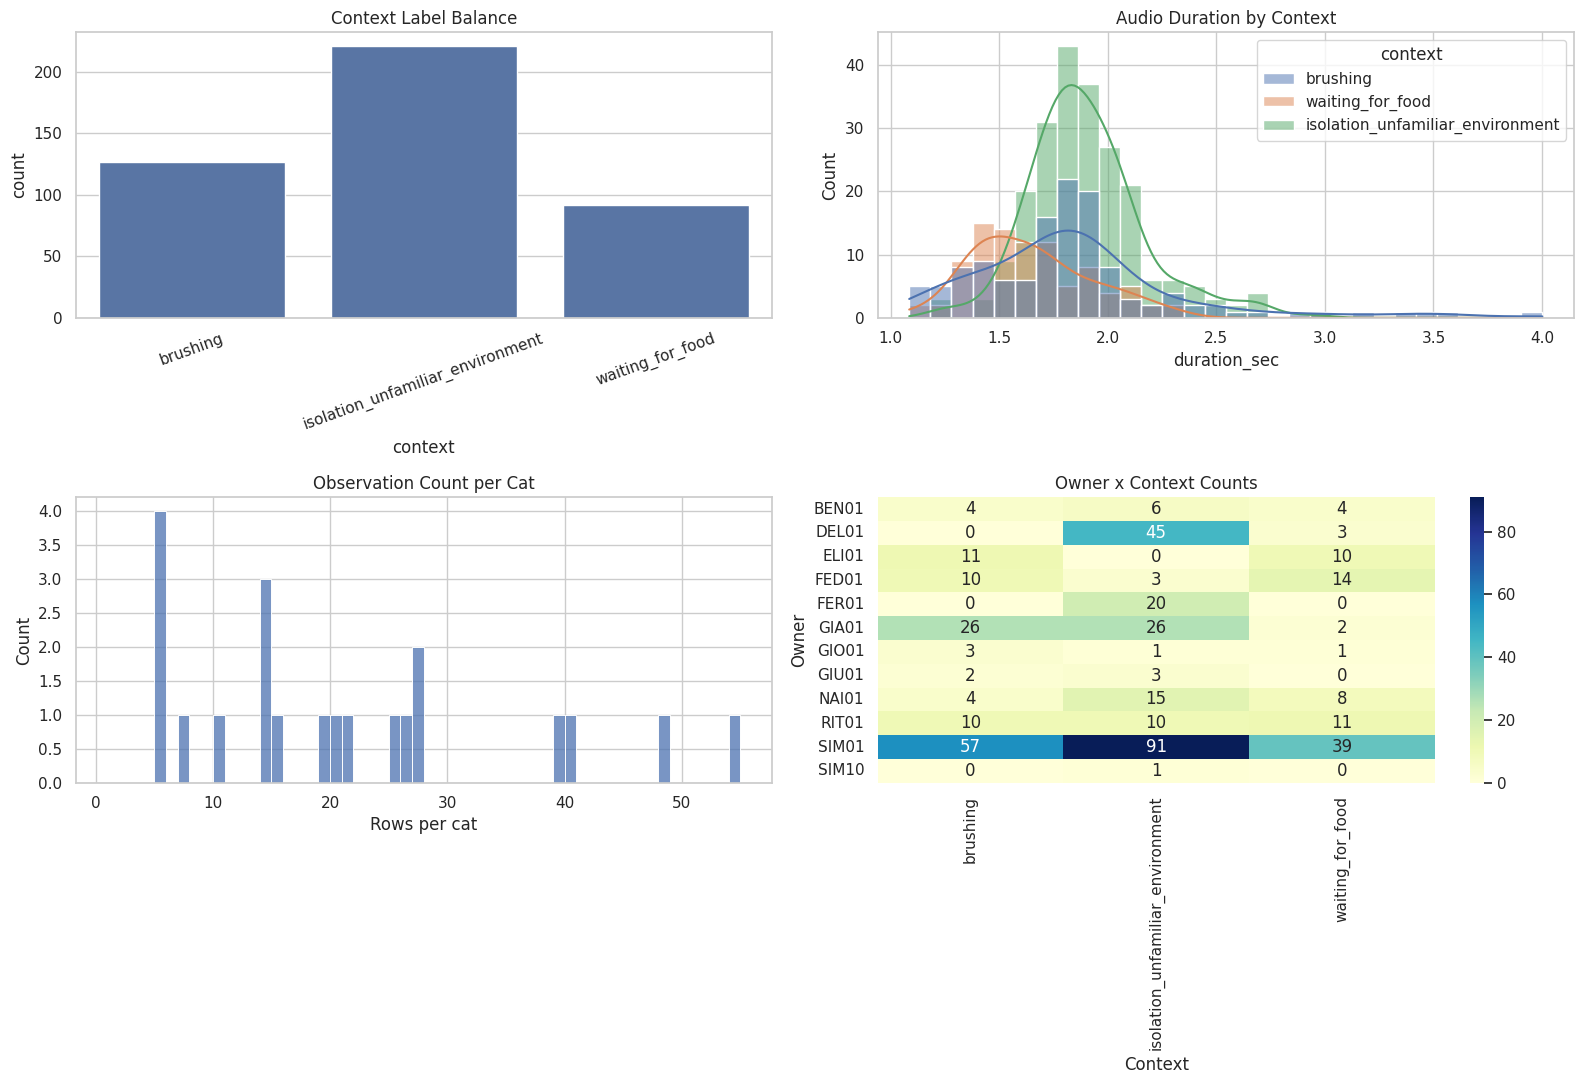

saved: /content/openfarm_catmeows/prepared/catmeows_visual_audit.png
{
  "generated_at": "2026-05-17T05:01:11.025610+00:00",
  "source_url": "https://zenodo.org/records/4008297",
  "doi": "10.5281/zenodo.4008297",
  "license": "cc-by-4.0",
  "rows": 440,
  "unique_cats": 21,
  "unique_owners": 12,
  "context_counts": {
    "brushing": 127,
    "waiting_for_food": 92,
    "isolation_unfamiliar_environment": 221
  },
  "breed_counts": {
    "Maine Coon": 188,
    "European Shorthair": 252
  },
  "sex_status_counts": {
    "female_neutered": 277,
    "male_neutered": 76,
    "female_intact": 68,
    "male_intact": 19
  },
  "duration_sec": {
    "min": 1.0855,
    "median": 1.8095625,
    "mean": 1.8310994318181817,
    "max": 4.0015,
    "total_minutes": 13.4280625
  },
  "leakage_policy": "Prepared examples use opaque audio filenames; source filenames are kept only in local source_mapping_private.csv."
}


In [6]:
#@title Dataset audit and visual diagnostics
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

manifest = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "source_url": ZENODO_RECORD_URL,
    "doi": record["metadata"].get("doi"),
    "license": record["metadata"].get("license", {}).get("id"),
    "rows": int(len(metadata_df)),
    "unique_cats": int(metadata_df["cat_id"].nunique()),
    "unique_owners": int(metadata_df["owner_id"].nunique()),
    "context_counts": dict(Counter(metadata_df["context"])),
    "breed_counts": dict(Counter(metadata_df["breed"])),
    "sex_status_counts": dict(Counter(metadata_df["sex_status"])),
    "duration_sec": {
        "min": float(metadata_df["duration_sec"].min()),
        "median": float(metadata_df["duration_sec"].median()),
        "mean": float(metadata_df["duration_sec"].mean()),
        "max": float(metadata_df["duration_sec"].max()),
        "total_minutes": float(metadata_df["duration_sec"].sum() / 60),
    },
    "leakage_policy": "Prepared examples use opaque audio filenames; source filenames are kept only in local source_mapping_private.csv.",
}
with (OUT_DIR / "dataset_audit.json").open("w") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
sns.countplot(data=metadata_df, x="context", order=CONTEXT_CHOICES, ax=axes[0, 0])
axes[0, 0].set_title("Context Label Balance")
axes[0, 0].tick_params(axis="x", rotation=20)

sns.histplot(data=metadata_df, x="duration_sec", hue="context", bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Audio Duration by Context")

cat_sizes = metadata_df.groupby("cat_id").size().reset_index(name="rows_per_cat")
sns.histplot(cat_sizes["rows_per_cat"], bins=range(1, int(cat_sizes["rows_per_cat"].max()) + 2), ax=axes[1, 0])
axes[1, 0].set_title("Observation Count per Cat")
axes[1, 0].set_xlabel("Rows per cat")

owner_context = pd.crosstab(metadata_df["owner_id"], metadata_df["context"])
sns.heatmap(owner_context, annot=True, cmap="YlGnBu", fmt="g", ax=axes[1, 1])
axes[1, 1].set_title("Owner x Context Counts")
axes[1, 1].set_xlabel("Context")
axes[1, 1].set_ylabel("Owner")

plt.tight_layout()
fig_path = OUT_DIR / "catmeows_visual_audit.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", fig_path)
print(json.dumps(manifest, indent=2, ensure_ascii=False))


In [7]:
#@title Build cat-heldout split and balanced train/test views
labels = metadata_df["context"].tolist()
groups = metadata_df["cat_id"].tolist()
base_counts = Counter(labels)
base_rate = {k: v / len(labels) for k, v in base_counts.items()}
unique_cat_count = metadata_df["cat_id"].nunique()
requested_test_cats = int(TEST_CAT_TARGET) if TEST_CAT_TARGET else max(1, round(unique_cat_count * TEST_SIZE_FALLBACK))
requested_test_cats = max(1, min(unique_cat_count - 1, requested_test_cats))
effective_test_size = requested_test_cats / unique_cat_count
print("unique cats:", unique_cat_count)
print("requested held-out cats:", requested_test_cats)
print("effective cat-level test size:", round(effective_test_size, 4))

best = None
for seed in range(SEED, SEED + 1000):
    splitter = GroupShuffleSplit(n_splits=1, test_size=effective_test_size, random_state=seed)
    train_idx, test_idx = next(splitter.split(metadata_df, labels, groups))
    train_part = metadata_df.iloc[train_idx]
    test_part = metadata_df.iloc[test_idx]
    train_cats = set(train_part["cat_id"])
    test_cats = set(test_part["cat_id"])
    assert train_cats.isdisjoint(test_cats)

    test_counts = Counter(test_part["context"])
    if len(test_counts) < len(base_counts):
        score = 999.0
    else:
        test_rate = {k: test_counts.get(k, 0) / len(test_part) for k in base_counts}
        score = sum(abs(test_rate[k] - base_rate[k]) for k in base_counts)
        score += abs(test_part["cat_id"].nunique() - requested_test_cats) / unique_cat_count
        score += abs(len(test_part) / len(metadata_df) - TEST_SIZE_FALLBACK) * 0.25
    candidate = (score, seed, train_part.index.tolist(), test_part.index.tolist())
    if best is None or candidate < best:
        best = candidate

score, split_seed, train_indices, test_indices = best
train_raw_df = metadata_df.loc[train_indices].copy()
test_raw_df = metadata_df.loc[test_indices].copy()
train_raw_df["split"] = "train_raw"
test_raw_df["split"] = "test_raw"


def make_balanced_view(frame: pd.DataFrame, split_name: str, seed: int) -> pd.DataFrame:
    counts = frame["context"].value_counts()
    n = int(counts.min())
    pieces = []
    for label in sorted(counts.index):
        pieces.append(frame[frame["context"] == label].sample(n=n, random_state=seed))
    out = pd.concat(pieces).sample(frac=1, random_state=seed).reset_index(drop=True)
    out["split"] = split_name
    return out

train_df = make_balanced_view(train_raw_df, "train", split_seed)
test_df = make_balanced_view(test_raw_df, "test", split_seed)

print("split seed:", split_seed, "score:", round(score, 4))
print("train_raw rows/cats:", len(train_raw_df), train_raw_df["cat_id"].nunique())
print("test_raw rows/cats:", len(test_raw_df), test_raw_df["cat_id"].nunique())
print("cat overlap:", set(train_raw_df["cat_id"]) & set(test_raw_df["cat_id"]))
print("train_raw labels:", Counter(train_raw_df["context"]))
print("test_raw labels:", Counter(test_raw_df["context"]))
print("train labels:", Counter(train_df["context"]))
print("test labels:", Counter(test_df["context"]))
print("test cats:", sorted(test_raw_df["cat_id"].unique()))

train_raw_df.to_csv(OUT_DIR / "catmeows_train_raw_metadata.csv", index=False)
test_raw_df.to_csv(OUT_DIR / "catmeows_test_raw_metadata.csv", index=False)
train_df.to_csv(OUT_DIR / "catmeows_train_metadata.csv", index=False)
test_df.to_csv(OUT_DIR / "catmeows_test_metadata.csv", index=False)


unique cats: 21
requested held-out cats: 6
effective cat-level test size: 0.2857
split seed: 786 score: 0.0101
train_raw rows/cats: 322 15
test_raw rows/cats: 118 6
cat overlap: set()
train_raw labels: Counter({'isolation_unfamiliar_environment': 162, 'brushing': 93, 'waiting_for_food': 67})
test_raw labels: Counter({'isolation_unfamiliar_environment': 59, 'brushing': 34, 'waiting_for_food': 25})
train labels: Counter({'waiting_for_food': 67, 'brushing': 67, 'isolation_unfamiliar_environment': 67})
test labels: Counter({'isolation_unfamiliar_environment': 25, 'brushing': 25, 'waiting_for_food': 25})
test cats: ['BRA01', 'CLE01', 'IND01', 'MEG01', 'NIG01', 'WHO01']


In [8]:
#@title Shallow acoustic baseline check
# This asks whether trivial acoustic summaries solve the context task.
# A strong model should beat both majority and shallow-feature baselines.

FEATURES = ["duration_sec", "rms_energy", "peak_abs_amplitude", "zero_crossing_rate", "spectral_centroid_hz"]
LABELS_ORDER = CONTEXT_CHOICES


def run_acoustic_baseline(train_frame: pd.DataFrame, test_frame: pd.DataFrame, name: str) -> dict:
    X_train = train_frame[FEATURES].astype(float).to_numpy()
    X_test = test_frame[FEATURES].astype(float).to_numpy()
    y_train = train_frame["context"].tolist()
    y_test = test_frame["context"].tolist()

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    majority = DummyClassifier(strategy="most_frequent")
    majority.fit(X_train_scaled, y_train)
    majority_pred = majority.predict(X_test_scaled)

    clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
    clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)

    print("\n" + "=" * 80)
    print(name)
    print("test label counts:", Counter(y_test))
    print("Majority baseline")
    print("accuracy:", round(accuracy_score(y_test, majority_pred), 4))
    print("balanced_accuracy:", round(balanced_accuracy_score(y_test, majority_pred), 4))
    print("\nSimple acoustic logistic regression")
    print("accuracy:", round(accuracy_score(y_test, pred), 4))
    print("balanced_accuracy:", round(balanced_accuracy_score(y_test, pred), 4))
    print("macro_f1:", round(f1_score(y_test, pred, labels=LABELS_ORDER, average="macro"), 4))
    print(classification_report(y_test, pred, labels=LABELS_ORDER, digits=3))
    print("confusion_matrix labels", LABELS_ORDER)
    print(confusion_matrix(y_test, pred, labels=LABELS_ORDER))
    return {
        "name": name,
        "features": FEATURES,
        "train_rows": len(train_frame),
        "test_rows": len(test_frame),
        "test_label_counts": dict(Counter(y_test)),
        "majority_accuracy": accuracy_score(y_test, majority_pred),
        "majority_balanced_accuracy": balanced_accuracy_score(y_test, majority_pred),
        "acoustic_accuracy": accuracy_score(y_test, pred),
        "acoustic_balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "acoustic_macro_f1": f1_score(y_test, pred, labels=LABELS_ORDER, average="macro"),
        "acoustic_confusion_matrix": confusion_matrix(y_test, pred, labels=LABELS_ORDER).tolist(),
    }

baseline_audit = {
    "balanced_split": run_acoustic_baseline(train_df, test_df, "Balanced published split: train/test"),
    "raw_split": run_acoustic_baseline(train_raw_df, test_raw_df, "Natural distribution split: train_raw/test_raw"),
}
with (OUT_DIR / "baseline_audit.json").open("w") as f:
    json.dump(baseline_audit, f, indent=2, ensure_ascii=False)
print("saved:", OUT_DIR / "baseline_audit.json")



Balanced published split: train/test
test label counts: Counter({'isolation_unfamiliar_environment': 25, 'brushing': 25, 'waiting_for_food': 25})
Majority baseline
accuracy: 0.3333
balanced_accuracy: 0.3333

Simple acoustic logistic regression
accuracy: 0.4533
balanced_accuracy: 0.4533
macro_f1: 0.444
                                  precision    recall  f1-score   support

                        brushing      0.250     0.200     0.222        25
isolation_unfamiliar_environment      0.469     0.600     0.526        25
                waiting_for_food      0.609     0.560     0.583        25

                        accuracy                          0.453        75
                       macro avg      0.442     0.453     0.444        75
                    weighted avg      0.442     0.453     0.444        75

confusion_matrix labels ['brushing', 'isolation_unfamiliar_environment', 'waiting_for_food']
[[ 5 13  7]
 [ 8 15  2]
 [ 7  4 14]]

Natural distribution split: train_raw/test_r

In [9]:
#@title Validate leakage guards and consolidate public dataset rows
# We validate that prepared filenames do not expose target labels.
# The actual chat prompt formatting, system prompt, and answer contract live in the verifiers environment.

split_frames = {
    "train": train_df,
    "test": test_df,
    "train_raw": train_raw_df,
    "test_raw": test_raw_df,
}

# Keep meaningful parsed/acoustic metadata. Drop only local bookkeeping and answer-encoded source filenames.
PUBLIC_FORBIDDEN_COLUMNS = {
    "source_filename",
    "source_archive_member",
    "source_filename_sha256",
    "context_code",
}

PUBLIC_COLUMNS = [
    "context",
    "cat_id",
    "owner_id",
    "breed",
    "breed_code",
    "sex_status",
    "sex_code",
    "recording_session",
    "vocalization_counter",
    "duration_sec",
    "sample_rate_hz",
    "channels",
    "sample_width_bytes",
    "frames",
    "rms_energy",
    "peak_abs_amplitude",
    "zero_crossing_rate",
    "spectral_centroid_hz",
    "audio_sha256",
]

consolidated_rows = []
for split_name, frame in split_frames.items():
    for _, row in frame.iterrows():
        assert row["context"] in CONTEXT_CHOICES
        assert row["opaque_audio_filename"].startswith("catmeows_")
        assert not row["opaque_audio_filename"].startswith(tuple(CONTEXT_MAP.keys()))

        audio_path = AUDIO_DIR / row["opaque_audio_filename"]
        assert audio_path.exists(), audio_path

        public_row = {col: row.get(col, "") for col in PUBLIC_COLUMNS}
        public_row["audio_filename"] = row["opaque_audio_filename"]
        public_row["audio"] = str(audio_path)
        public_row["source_url"] = ZENODO_RECORD_URL
        public_row["source_doi"] = record["metadata"].get("doi") or ""
        public_row["license"] = "cc-by-4.0"
        public_row["split"] = split_name
        consolidated_rows.append(public_row)

hf_df = pd.DataFrame(consolidated_rows)
assert not (PUBLIC_FORBIDDEN_COLUMNS & set(hf_df.columns)), PUBLIC_FORBIDDEN_COLUMNS & set(hf_df.columns)

hf_path = OUT_DIR / "catmeows_hf_dataset.jsonl"
hf_df.to_json(hf_path, orient="records", lines=True, force_ascii=False)

print("dataset total rows:", len(hf_df))
print("public columns:", list(hf_df.columns))
print("wrote:", hf_path)
display(hf_df[["audio_filename", "split", "context", "cat_id", "owner_id", "breed", "recording_session", "duration_sec"]].head())


dataset total rows: 716
public columns: ['context', 'cat_id', 'owner_id', 'breed', 'breed_code', 'sex_status', 'sex_code', 'recording_session', 'vocalization_counter', 'duration_sec', 'sample_rate_hz', 'channels', 'sample_width_bytes', 'frames', 'rms_energy', 'peak_abs_amplitude', 'zero_crossing_rate', 'spectral_centroid_hz', 'audio_sha256', 'audio_filename', 'audio', 'source_url', 'source_doi', 'license', 'split']
wrote: /content/openfarm_catmeows/prepared/catmeows_hf_dataset.jsonl


,audio_filename,split,context,cat_id,owner_id,breed,recording_session,duration_sec
0,catmeows_0147.wav,train,waiting_for_food,BRI01,SIM01,Maine Coon,1,1.517125
1,catmeows_0072.wav,train,brushing,JJX01,SIM01,Maine Coon,2,1.894750
2,catmeows_0132.wav,train,waiting_for_food,BAC01,SIM01,Maine Coon,1,1.440500
3,catmeows_0087.wav,train,brushing,MAT01,RIT01,European Shorthair,2,1.468500
4,catmeows_0338.wav,train,isolation_unfamiliar_environment,DAK01,SIM01,Maine Coon,1,1.714625


In [10]:
#@title Build Hugging Face DatasetDict preview
split_datasets = {}
for split_name in ["train", "test", "train_raw", "test_raw"]:
    # Filter by split and drop the split column itself (redundant in DatasetDict)
    frame = hf_df[hf_df["split"] == split_name].drop(columns=["split"]).reset_index(drop=True)
    split_datasets[split_name] = Dataset.from_pandas(frame, preserve_index=False)

ds = DatasetDict(split_datasets)

# Cast audio paths to real HF Audio columns so push_to_hub can package media.
# decode=False avoids requiring local audio decoding backends during the preview/push step.
ds = ds.cast_column("audio", Audio(sampling_rate=None, decode=False))

print(ds)
preview = ds["train"][0].copy()
preview["audio"] = {k: preview["audio"].get(k) for k in ["path", "bytes"] if k in preview["audio"]}
print(preview)

DatasetDict({
    train: Dataset({
        features: ['context', 'cat_id', 'owner_id', 'breed', 'breed_code', 'sex_status', 'sex_code', 'recording_session', 'vocalization_counter', 'duration_sec', 'sample_rate_hz', 'channels', 'sample_width_bytes', 'frames', 'rms_energy', 'peak_abs_amplitude', 'zero_crossing_rate', 'spectral_centroid_hz', 'audio_sha256', 'audio_filename', 'audio', 'source_url', 'source_doi', 'license'],
        num_rows: 201
    })
    test: Dataset({
        features: ['context', 'cat_id', 'owner_id', 'breed', 'breed_code', 'sex_status', 'sex_code', 'recording_session', 'vocalization_counter', 'duration_sec', 'sample_rate_hz', 'channels', 'sample_width_bytes', 'frames', 'rms_energy', 'peak_abs_amplitude', 'zero_crossing_rate', 'spectral_centroid_hz', 'audio_sha256', 'audio_filename', 'audio', 'source_url', 'source_doi', 'license'],
        num_rows: 75
    })
    train_raw: Dataset({
        features: ['context', 'cat_id', 'owner_id', 'breed', 'breed_code', 'sex_statu

In [11]:
#@title Dataset card scaffold
train_counts = dict(Counter(train_df["context"]))
test_counts = dict(Counter(test_df["context"]))
train_raw_counts = dict(Counter(train_raw_df["context"]))
test_raw_counts = dict(Counter(test_raw_df["context"]))
all_counts = dict(Counter(metadata_df["context"]))

card = f"""---
license: cc-by-4.0
language:
- en
pretty_name: OpenFARM CatMeows Audio Context
size_categories:
- n<1K
tags:
- animal-welfare
- cat
- feline
- audio
- bioacoustics
- openfarm
---

# OpenFARM CatMeows Audio Context

This prepared dataset derives from CatMeows: A Publicly-Available Dataset of Cat Vocalizations.

Source: {ZENODO_RECORD_URL}
DOI: {record['metadata'].get('doi')}
Source title: {record['metadata'].get('title')}
Source license: CC-BY-4.0
Prepared: {datetime.now(timezone.utc).date().isoformat()}

## Scope

This is a feline **audio context-classification** dataset. Given a short cat vocalization, predict the eliciting context:

- `brushing`
- `isolation_unfamiliar_environment`
- `waiting_for_food`

These labels are source elicitation contexts. They are not clinical labels, pain scores, stress diagnoses, or validated welfare outcomes. `isolation_unfamiliar_environment` can support analysis of an unfamiliar-isolation recording condition, but model outputs should not be described as direct diagnoses of stress, pain, disease, or overall welfare from this dataset alone.

## Source Processing Summary

- Main source WAV files: {len(metadata_df)}
- Cats: {metadata_df['cat_id'].nunique()}
- Owners: {metadata_df['owner_id'].nunique()}
- Total audio duration: {metadata_df['duration_sec'].sum() / 60:.2f} minutes
- Source label counts: {all_counts}
- Audio format: mono WAV, 8 kHz, 16-bit PCM

## Data Shape

Each public row is one prepared audio clip plus minimal metadata for grouping and auditing. The environment evaluating this dataset is responsible for mapping these columns into a multimodal prompt. DatasetDict split membership is stored by split name, so the `split` column is not included inside each public split.

Main fields:

- `audio`: HF `Audio` feature with the prepared WAV file
- `audio_filename`: opaque prepared filename, not the source filename
- `context`: target context label, one of `brushing`, `isolation_unfamiliar_environment`, or `waiting_for_food`
- `cat_id`, `owner_id`: source grouping IDs for cat-heldout and owner-aware leakage auditing; keep these out of primary model prompts unless running an explicit metadata ablation
- `breed`, `breed_code`, `sex_status`, `sex_code`, `recording_session`, `vocalization_counter`: parsed source metadata for analysis and ablations; these fields may correlate with source collection structure and should not be treated as neutral clinical features
- `duration_sec`, `sample_rate_hz`, `channels`, `sample_width_bytes`, `frames`: basic audio metadata
- `rms_energy`, `peak_abs_amplitude`, `zero_crossing_rate`, `spectral_centroid_hz`: lightweight acoustic summary features used by the baseline audit
- `audio_sha256`: hash of the prepared audio file
- `source_url`, `source_doi`, `license`: source attribution fields

## Leakage Policy

Original CatMeows filenames encode the context label, cat ID, breed, sex, owner, session, and vocalization counter. Prepared media files are therefore renamed to opaque filenames such as `catmeows_0001.wav`.

The public rows include the target `context` column for scoring and parsed metadata for audits. Primary environment prompts should provide the audio and task options, not the target label, original filename metadata, or metadata fields that trivially identify or strongly proxy the context.

Recommended prompt framing: ask for the most likely source dataset context from the fixed options, and state that the task is not a clinical or welfare diagnosis.

## Splits

Splits are cat-heldout at the raw train/test boundary. No `cat_id` appears in both raw train and raw test.

Prepared splits:

- `train`: class-balanced view sampled from the cat-heldout raw train set; counts {train_counts}
- `test`: class-balanced view sampled from the cat-heldout raw test set; counts {test_counts}
- `train_raw`: natural cat-heldout train distribution; counts {train_raw_counts}
- `test_raw`: natural cat-heldout test distribution; counts {test_raw_counts}

Use `train`/`test` for balanced OpenFARM env development and quick model comparisons. Use `train_raw`/`test_raw` when reporting behavior on the source distribution.

## Metrics

Recommended metrics:

- overall accuracy
- balanced accuracy
- macro F1
- per-class precision/recall/F1
- confusion matrix
- majority-class baseline
- shallow acoustic-feature baseline from `baseline_audit.json`

## Limitations

The labels are eliciting contexts, not direct welfare or pain labels. The dataset is small and contains repeated calls from the same cats, so subject-heldout evaluation is important.
"""

card_path = OUT_DIR / "README.md"
card_path.write_text(card)
print(card)


---
license: cc-by-4.0
language:
- en
pretty_name: OpenFARM CatMeows Audio Context
size_categories:
- n<1K
tags:
- animal-welfare
- cat
- feline
- audio
- bioacoustics
- openfarm
---

# OpenFARM CatMeows Audio Context

This prepared dataset derives from CatMeows: A Publicly-Available Dataset of Cat Vocalizations.

Source: https://zenodo.org/records/4008297
DOI: 10.5281/zenodo.4008297
Source title: CatMeows: A Publicly-Available Dataset of Cat Vocalizations
Source license: CC-BY-4.0
Prepared: 2026-05-17

## Scope

This is a feline **audio context-classification** dataset. Given a short cat vocalization, predict the eliciting context:

- `brushing`
- `isolation_unfamiliar_environment`
- `waiting_for_food`

These labels are source elicitation contexts. They are not clinical labels, pain scores, stress diagnoses, or validated welfare outcomes. `isolation_unfamiliar_environment` can support analysis of an unfamiliar-isolation recording condition, but model outputs should not be described as

In [12]:
#@title Optional push to Hugging Face Hub
# Keep PUSH_TO_HUB=False while iterating. This cell does not print tokens.

if PUSH_TO_HUB:
    token = os.environ.get("HF_TOKEN")
    if token is None:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")
        except Exception:
            token = None
    if token:
        login(token=token, add_to_git_credential=False)
    else:
        print("No HF_TOKEN found. You can run huggingface-cli login or set HF_TOKEN, then rerun this cell.")

    api = HfApi()
    api.create_repo(repo_id=HF_REPO_ID, repo_type="dataset", private=PRIVATE_REPO, exist_ok=True)
    ds.push_to_hub(HF_REPO_ID, private=PRIVATE_REPO)
    api.upload_file(
        path_or_fileobj=str(OUT_DIR / "README.md"),
        path_in_repo="README.md",
        repo_id=HF_REPO_ID,
        repo_type="dataset",
    )
    print("pushed:", f"https://huggingface.co/datasets/{HF_REPO_ID}")
else:
    print("dry run only. Set PUSH_TO_HUB=True after reviewing outputs.")


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/201 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/3 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 3.15MB / 3.15MB            

README.md: 0.00B [00:00, ?B/s]

pushed: https://huggingface.co/datasets/oliveirabruno01/openfarm-catmeows


# Review checklist

Before using this as an OpenFARM env dataset:

- review `dataset_audit.json` and `baseline_audit.json`
- inspect several audio/label pairs manually
- confirm no cat ID appears across `train_raw` and `test_raw`
- confirm public rows do not expose source filenames
- use `train`/`test` as the balanced env-facing splits unless you explicitly want source-distribution scoring
- report balanced accuracy, macro F1, and per-class recall
- preserve source attribution and CC-BY-4.0 license metadata
